# Smart Microscopy v3.1 — Adaptive Target Acquisition

Acquire an overview scan at the source objective, segment cells, pick targets from the cell distribution, then re-acquire those targets at the target objective.

## Workflow

| Step | What it does | Before you run it |
|------|--------------|-------------------|
| 1. Initialization | Connect, validate, boot the engine | Connect LAS X |
| 2a. Define limits | Derive XY stage limits | Place boundary markers |
| 2b. Define positions | Read the scan-field tiles | Draw the scan field |
| 2c. Define focus map | Fit a z-wide focus surface | Place focus markers |
| 3. Acquire overview | Scan and segment every tile | — |
| 4. Target discovery | Pick targets from the distribution | — |
| 5. Target acquisition | Re-acquire targets at high magnification | — |
| 6. Finish | Write the summary, plot, shut down | — |

All workflow logic lives in `notebooks/workflow/`; this notebook is a thin wrapper. See `docs/TARGET_ACQUISITION_DESIGN.md` for the design.

## Configuration

Edit the cell below for your experiment, then run the steps in order.

`simulate=True` is a **simulator-only dry run**: every saved `.ome.tiff` from Step 3 and Step 5 has its pixels swapped for mock content (`mock_image_source` picks the source) under the original LAS X simulator's OME envelope, so the rest of the pipeline behaves identically to a real acquisition. A per-frame `SystemTypeName="SIMULATOR"` guard hard-aborts the run if any frame is not from the simulator — `simulate=True` cannot touch real-instrument data.

**Before a real run:** set `simulate=False`, check each job's objective in LAS X, and set the z-galvo to 0.

In [1]:
from _workflow_bootstrap import Config, Path

cfg = Config(
    # Jobs (each has an objective configured in LAS X)
    acquisition_job="Overview",
    target_job="HiRes",
    af_job="AF Job",

    # Paths
    analysis_repo=Path(r"Z:\zmbstaff\10374\Protocols_Notes\thom\notes\repositories\smart-analysis"),
    experiment="v3-test",   # driver derives output_root as media_path/smart

    # Simulator dry run (LAS X simulator only). When True, every saved
    # .ome.tiff from Step 3 / Step 5 has its pixels overwritten with
    # mock content; the OME envelope, naming, layout, and analysis flow
    # are otherwise unchanged. The per-frame SystemTypeName=="SIMULATOR"
    # guard makes this unsafe to enable on real hardware -- the run
    # hard-aborts on the first non-simulator frame.
    simulate=False,
    mock_image_source=None,
    # simulate=True,
    # mock_image_source="skimage_human_mitosis",
)

## Step 1 — Initialization

Connects to LAS X, validates hardware and calibration, derives objective slots, and boots the analysis engine.

**Before running:** connect LAS X.

In [2]:
from workflow import connect_lasx, preflight

client = connect_lasx()
ctx = preflight(cfg, client)


[job] 'Overview' selected (slot 1)
[step 1] preflight ok
  templates_dir : C:\Users\t.de\AppData\Roaming\Leica Microsystems\LAS X\MatrixScreener6\User_0\ScanningTemplates
  out_dir       : E:\smart\v3-test_076t08
  current_job   : Overview  (slot 1)
  target_job    : HiRes  (slot 0)
  source z-galvo: -0.000 um
  cellpose env  : present


## Step 2 — Setup overview

Configure the overview scan's spatial extent. Run 2a → 2b → 2c in order.

### Step 2a — Define limits

Derives XY stage limits from boundary markers (or uses the physical envelope if none are placed) and forces every job to z-wide.

**Before running:** place point markers at the sample corners in Navigator Expert, or skip to use the physical envelope.

[step 2a] Stage limits from 4 boundary marker(s) (envelope from stage.json):
  X: 27453 - 37029 um
  Y: 14642 - 22865 um
  z-wide: 0 - 25000 um (from stage.json)
[step 2a] Template stripped and z-wide enforced on every job.
[step 2a] Saved E:\smart\v3-test_076t08\initialization\logs\stage_envelope.png


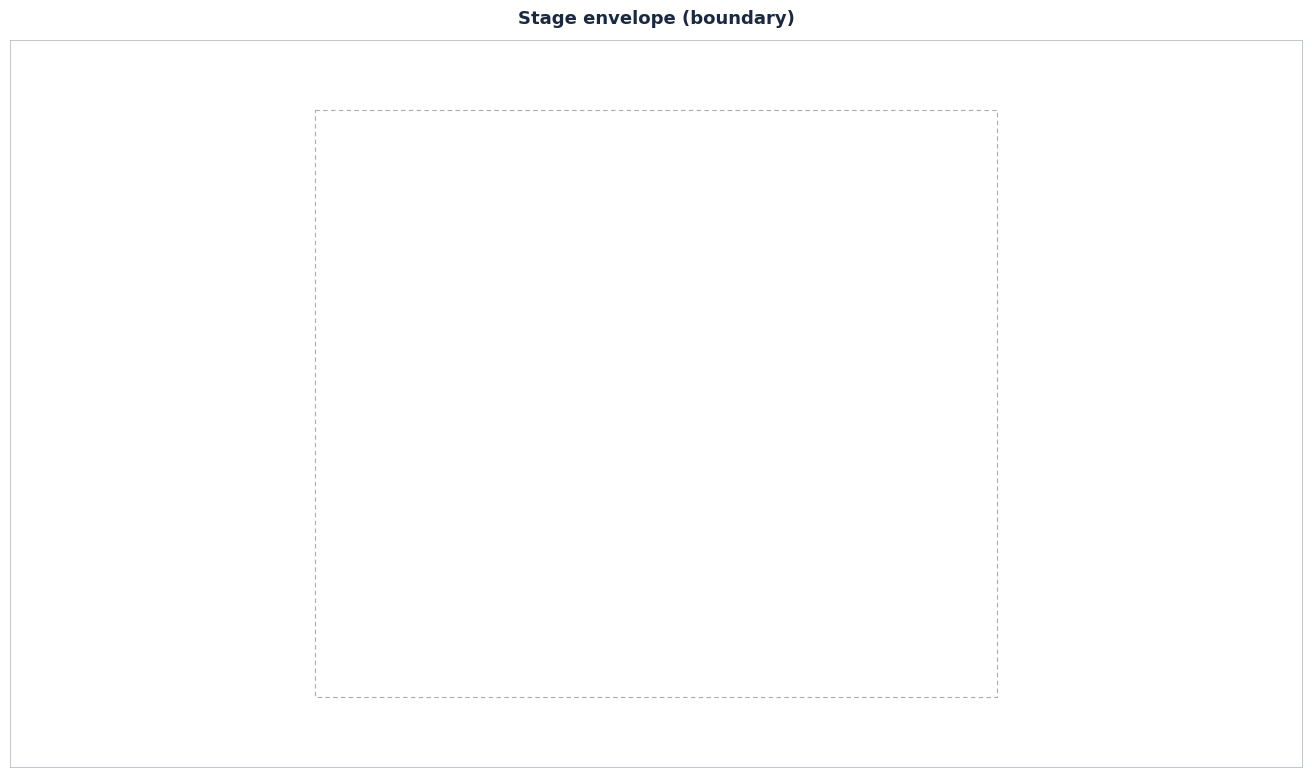

In [3]:
from workflow import prepare_template, plot_stage_envelope

prepare_template(ctx)
plot_stage_envelope(ctx)

### Step 2b — Define positions

Reads the scan field you drew — it defines which tiles the overview acquires.

**Before running:** draw the scan field in Navigator Expert.

[step 2b] Synthesized 9 tiles from geometries (tile size 1160.0 um)
[step 2b] Scan field: 1 group(s), 9 tile(s)
  Group 0: Overview  1x9  tile=1160.0 um
[step 2b] Saved E:\smart\v3-test_076t08\initialization\logs\overview_field.png


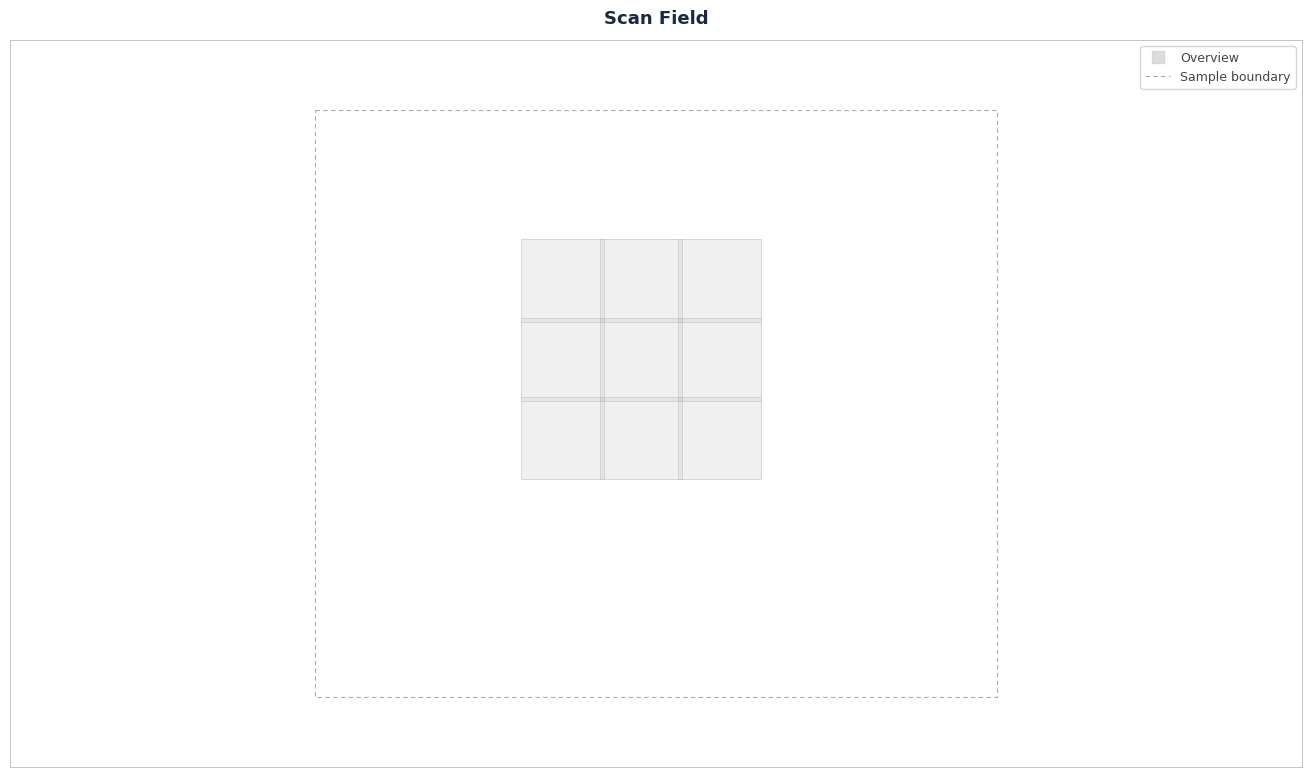

In [4]:
from workflow import read_scan_field, plot_scan_field

read_scan_field(ctx)
plot_scan_field(ctx)

### Step 2c — Define focus map

Runs autofocus at each focus marker and fits a z-wide surface across the scan field.

**Before running:** place focus markers on the scan field in Navigator Expert.

[step 2c] Focus positions (3):
  1. x=31320.9  y=17111.2 um
  2. x=31936.8  y=19019.5 um
  3. x=32879.5  y=17575.0 um
[job] 'AF Job' selected (slot 1)

[1/3] x=31321  y=17111  z-wide=6199.23 um

[2/3] x=31937  y=19020  z-wide=6200.23 um

[3/3] x=32880  y=17575  z-wide=6183.23 um

[step 2c] Focus model: plane (3 points)
  Z range:      17.00 um
  Tilt X:       -0.6605 deg
  Tilt Y:       +0.2432 deg
  Max residual: 0.000 um
[step 2c] Saved E:\smart\v3-test_076t08\initialization\logs\focus_map.png


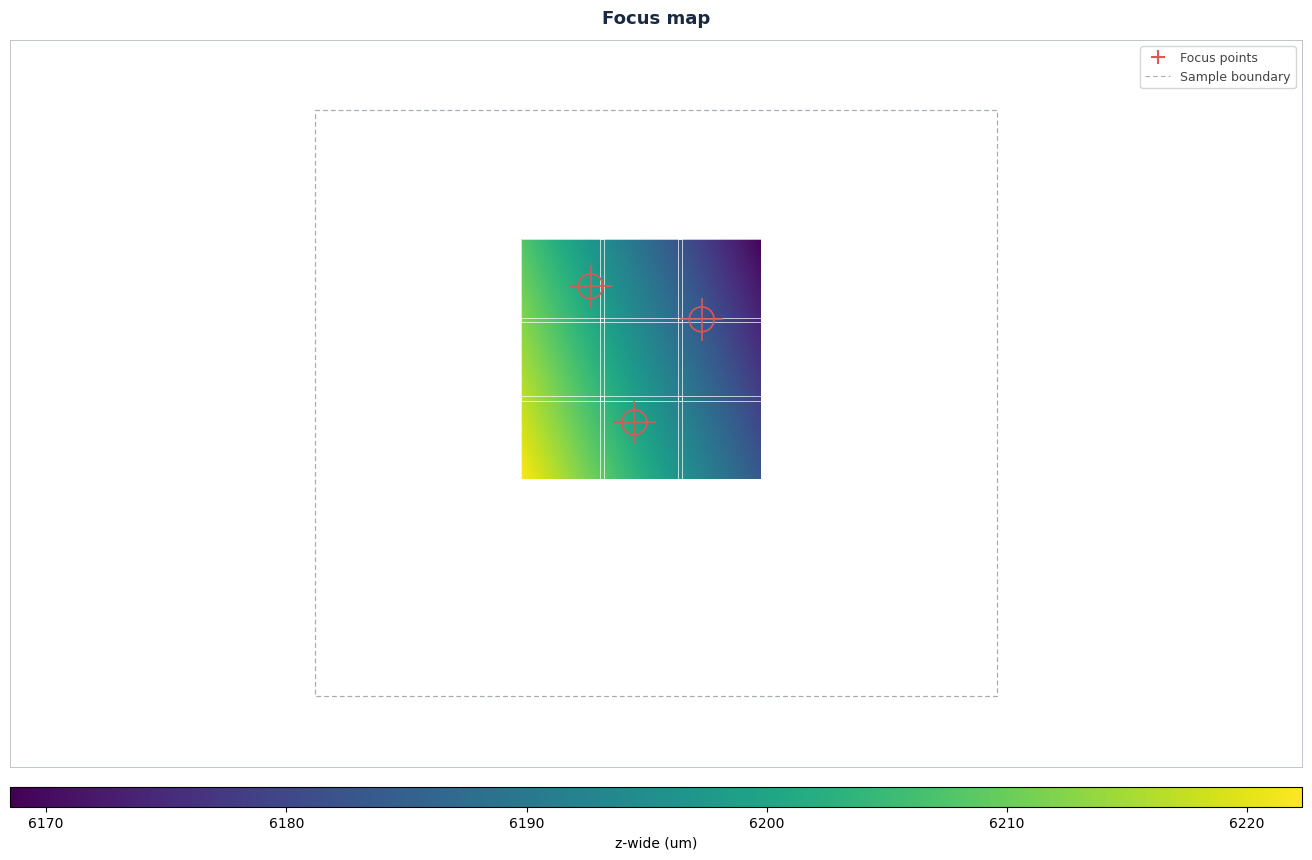

In [5]:
from workflow import build_focus_map

focus_map = build_focus_map(ctx)
focus_map.plot(ctx)

## Step 3 — Object Detection

Acquires every tile in snake order, segments each with cellpose, and writes the per-tile results to disk. Each tile is shown inline.

get_jobs: attempt 1/3 timed out


[job] 'Overview' selected (slot 1)
[step 3] 9 tiles in snake order
[1/9] Group 0, Position 0  x=30926 y=17032 z=6203.45  ok
[2/9] Group 0, Position 1  x=30926 y=18134 z=6208.12  ok
[3/9] Group 0, Position 2  x=30926 y=19236 z=6212.80  ok
[4/9] Group 0, Position 3  x=32028 y=17032 z=6190.74  ok


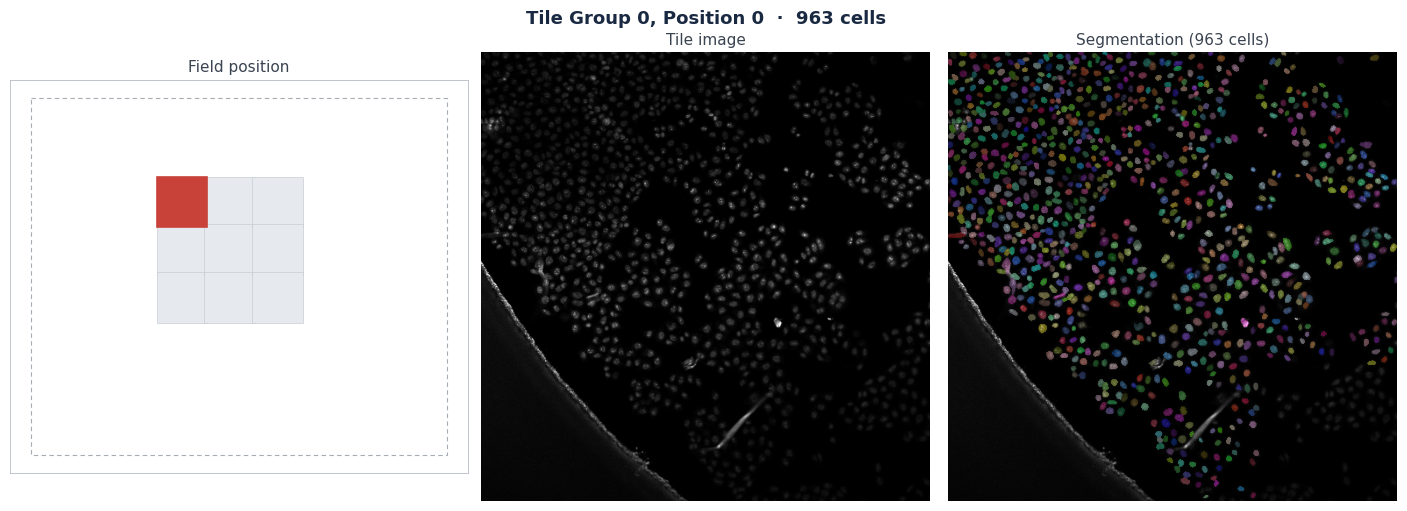

[5/9] Group 0, Position 4  x=32028 y=18134 z=6195.42  ok
[6/9] Group 0, Position 5  x=32028 y=19236 z=6200.10  ok
[7/9] Group 0, Position 6  x=33130 y=17032 z=6178.04  ok


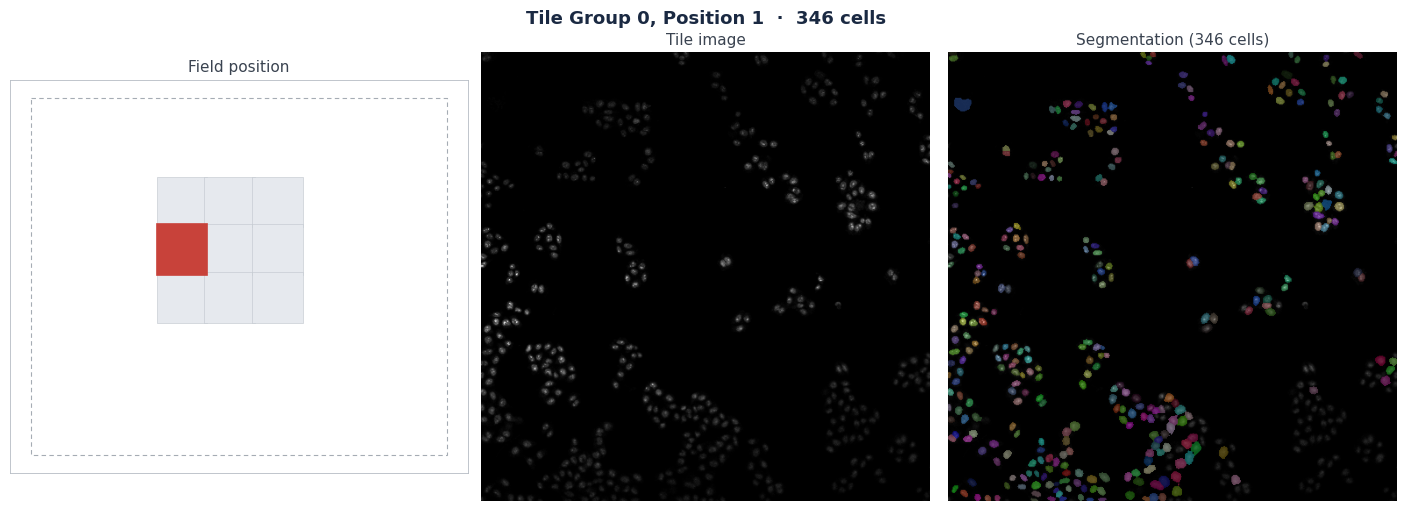

[8/9] Group 0, Position 7  x=33130 y=18134 z=6182.71  ok


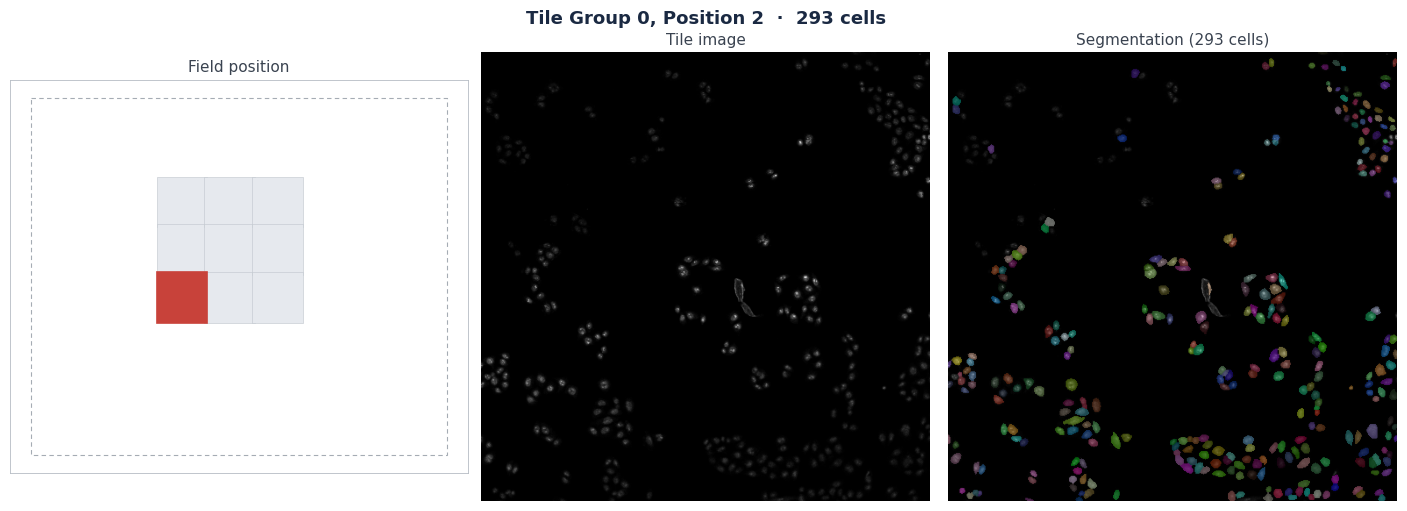

[9/9] Group 0, Position 8  x=33130 y=19236 z=6187.39  ok


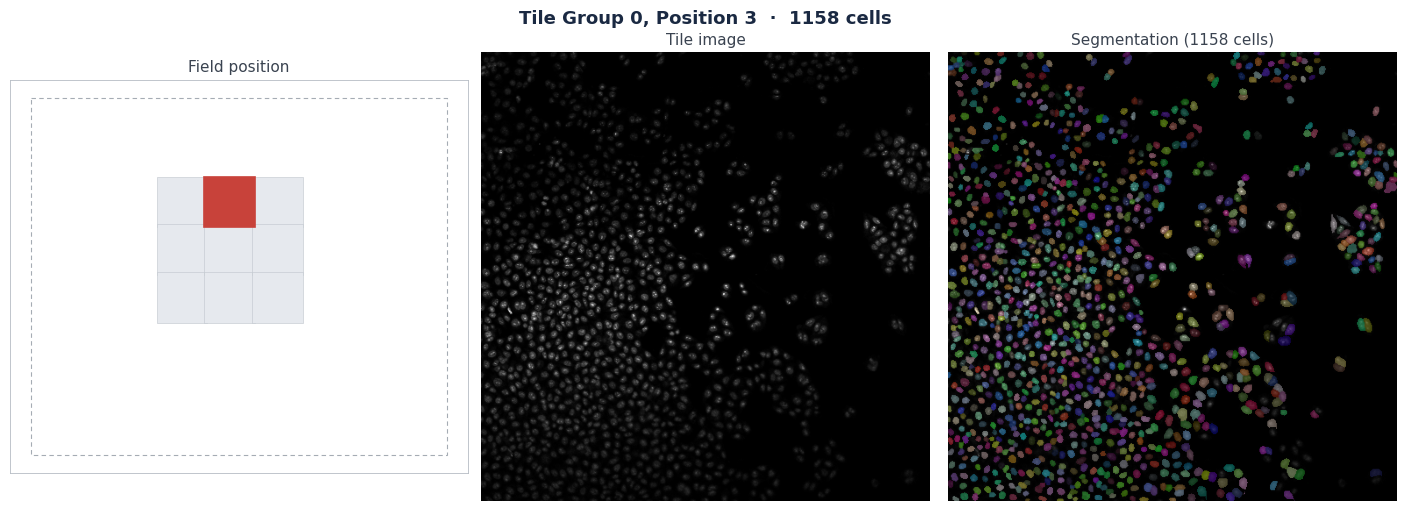

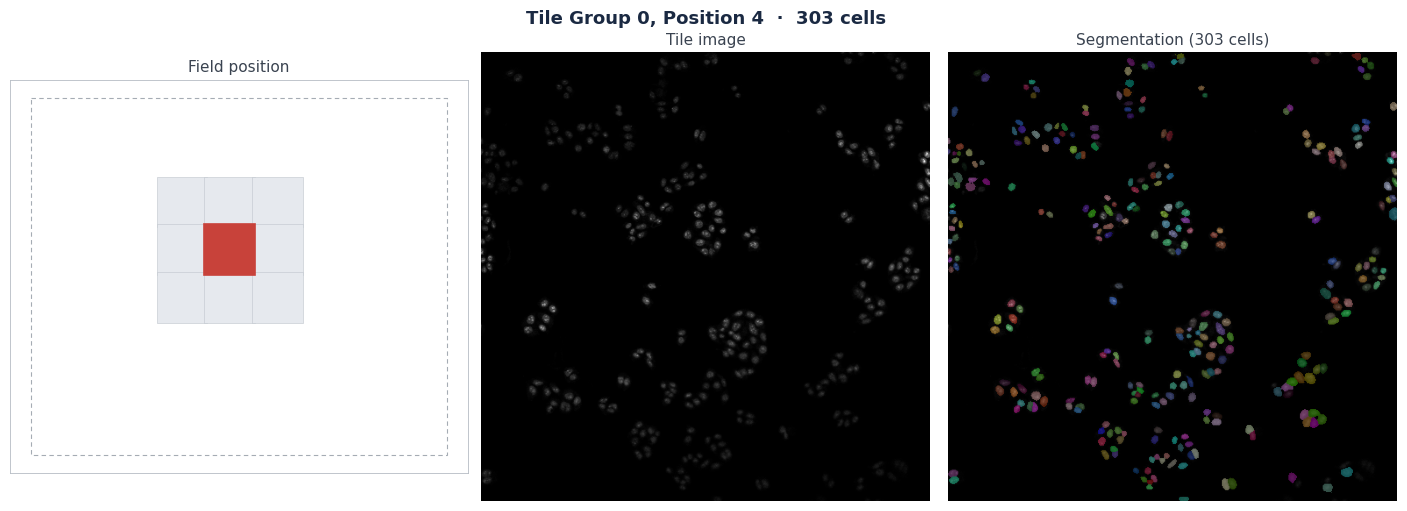

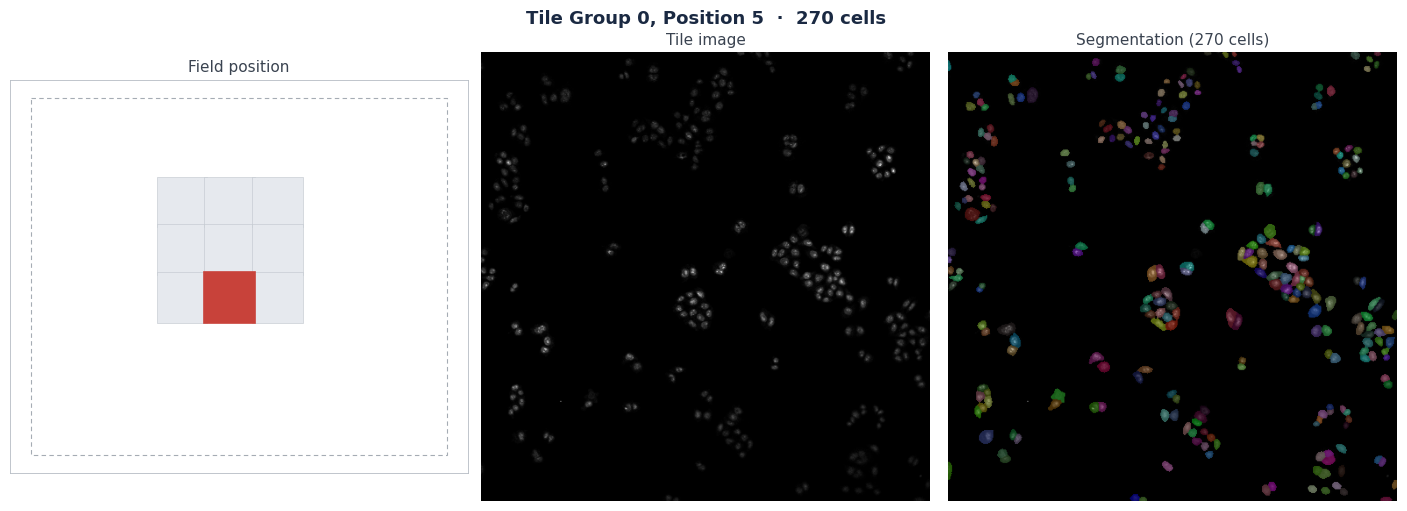

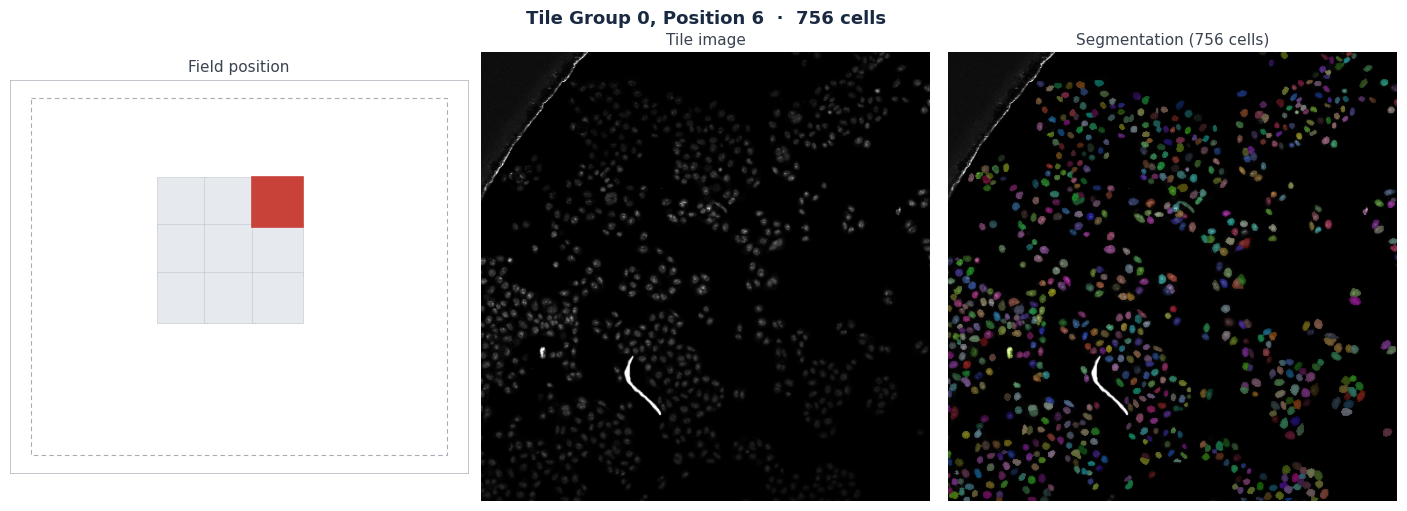

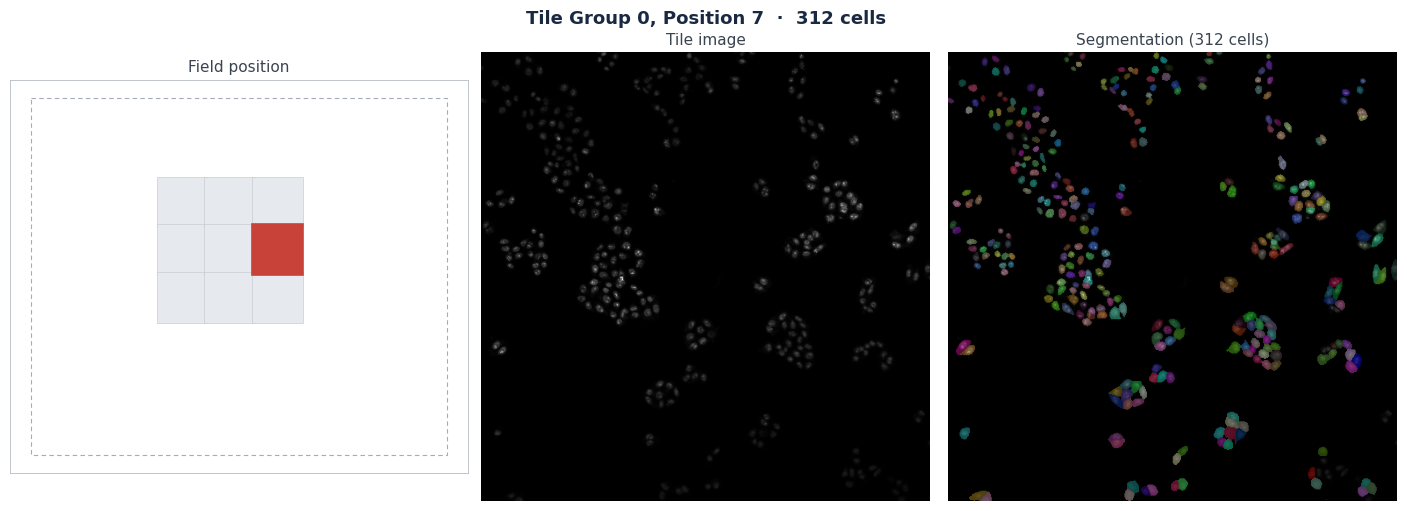

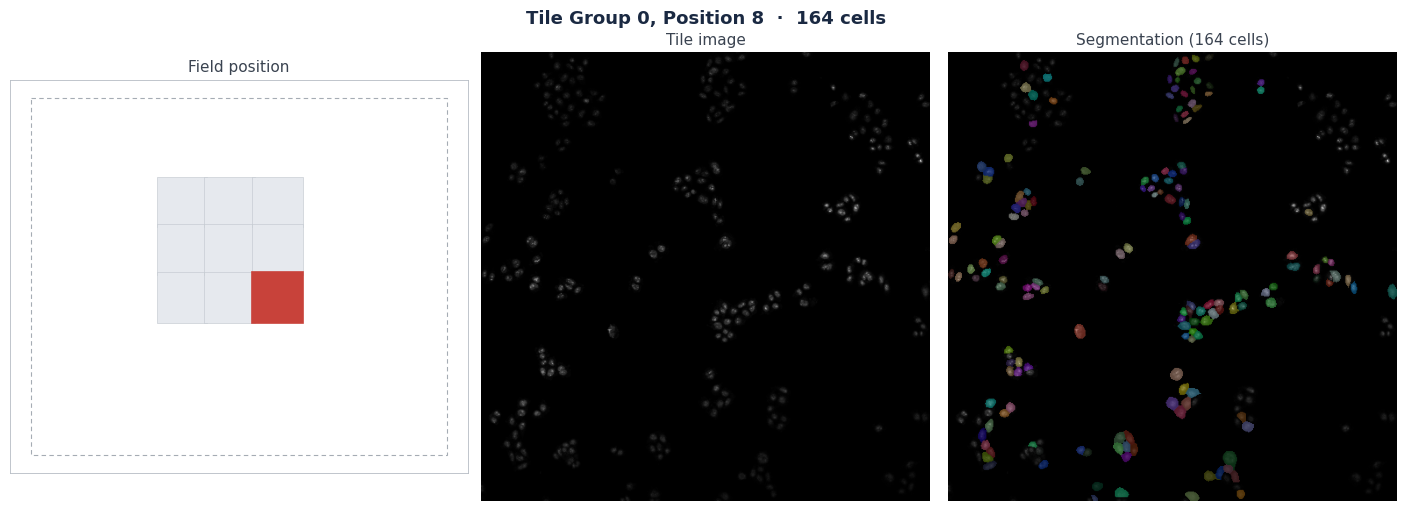


[step 3] Drain complete: 9 result(s), 0 engine failure(s), 0 tile acquire failure(s), 0 npz save failure(s). 9 tile(s) persisted.
[step 3] Template restored.


In [6]:
from workflow import run_overview

overview = run_overview(ctx, focus_map)

## Step 4 — Target discovery

Loads the overview, applies area / intensity thresholds, and picks target cells — shown as a scatter plus example crops.

Re-run with different `area_threshold`, `intensity_threshold`, `n_per_tile`, or `border_margin_px` to iterate without re-acquiring the overview.

[step 4] mode=threshold, total=4565 (2040 near-border excluded), qualifying=26, selected_pre_dedup=15, final=15 (area_threshold=100.0 override, intensity_threshold=30.0 override, border_margin_px=64)


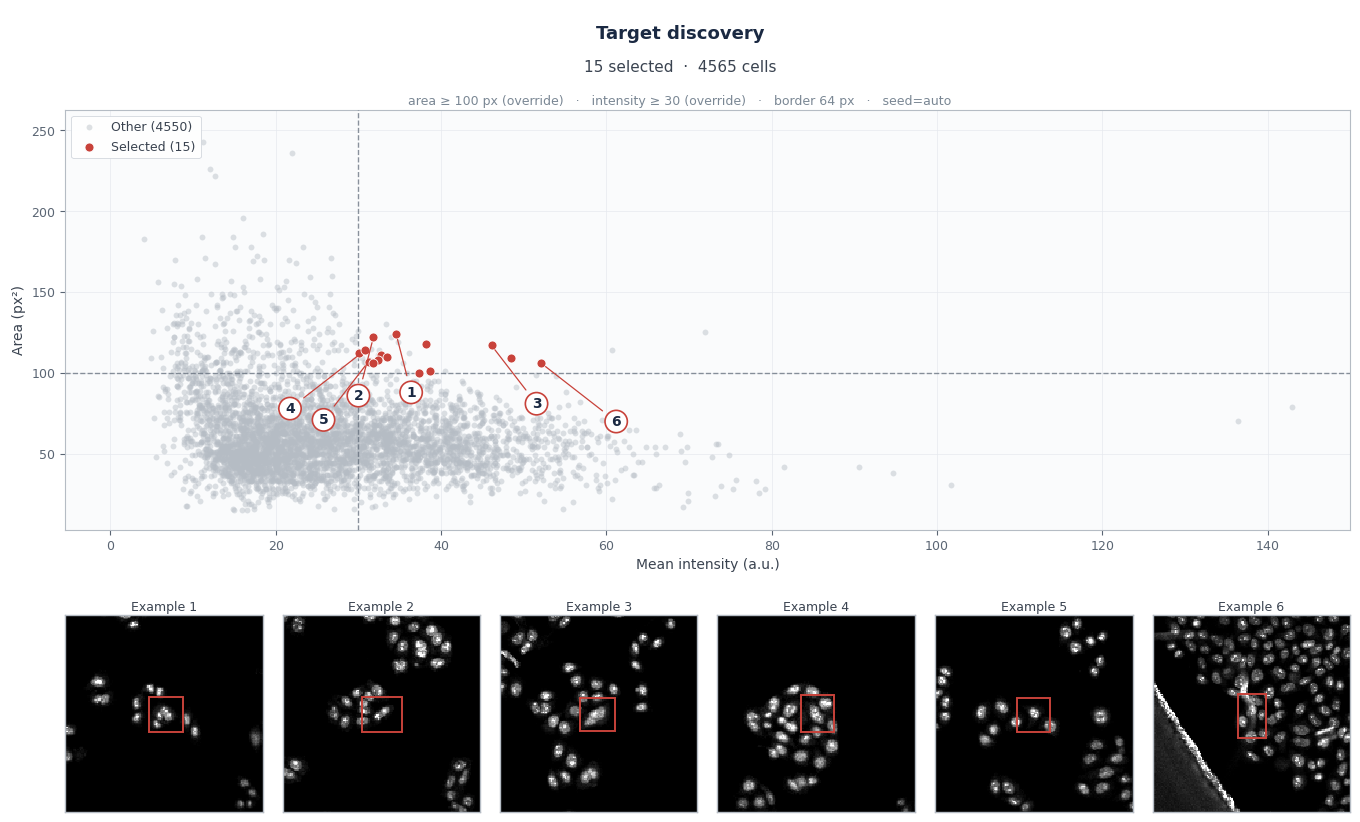

In [10]:
from workflow.selection import select_targets, load_overview_result
from workflow.visualize import display_selection

_analysis_dir = ctx.run.layout.analysis_dir("overview-scan")
overview = load_overview_result(_analysis_dir)   # kernel-restart safe

# Auto thresholds by default; uncomment to override. border_margin_px=64
# excludes cells whose bbox is within 64 px of any tile edge -- they have
# truncated stats and produce unreliable picks. Set to 0 to disable.
picks, selection = select_targets(
    overview,
    ctx.limits_context(),
    n_per_tile=2,
    border_margin_px=64,
    area_threshold=100,
    intensity_threshold=30,
    # seed=42,
)

display_selection(
    selection, _analysis_dir,
    logs_dir=ctx.run.layout.logs_dir("overview-scan"),
)

## Step 5 — Target acquisition

Switches to the target job and re-acquires each picked cell at high magnification; a failed pick does not stop the rest.

get_jobs: attempt 1/3 timed out
get_jobs: attempt 2/3 timed out
get_jobs: attempt 3/3 timed out
get_jobs: all 3 attempts failed
get_jobs: attempt 1/3 timed out
get_jobs: attempt 2/3 timed out
get_jobs: attempt 3/3 timed out
get_jobs: all 3 attempts failed
Job selection timeout after 5.0s for 'HiRes'
get_jobs: attempt 1/3 timed out


[job] 'HiRes' selected (slot 0)
[step 5] 15 picks to acquire at slot 0
[1/15] Group 0, Position 2, label 151  src=(30652, 18863)  ok  tz=6215.5


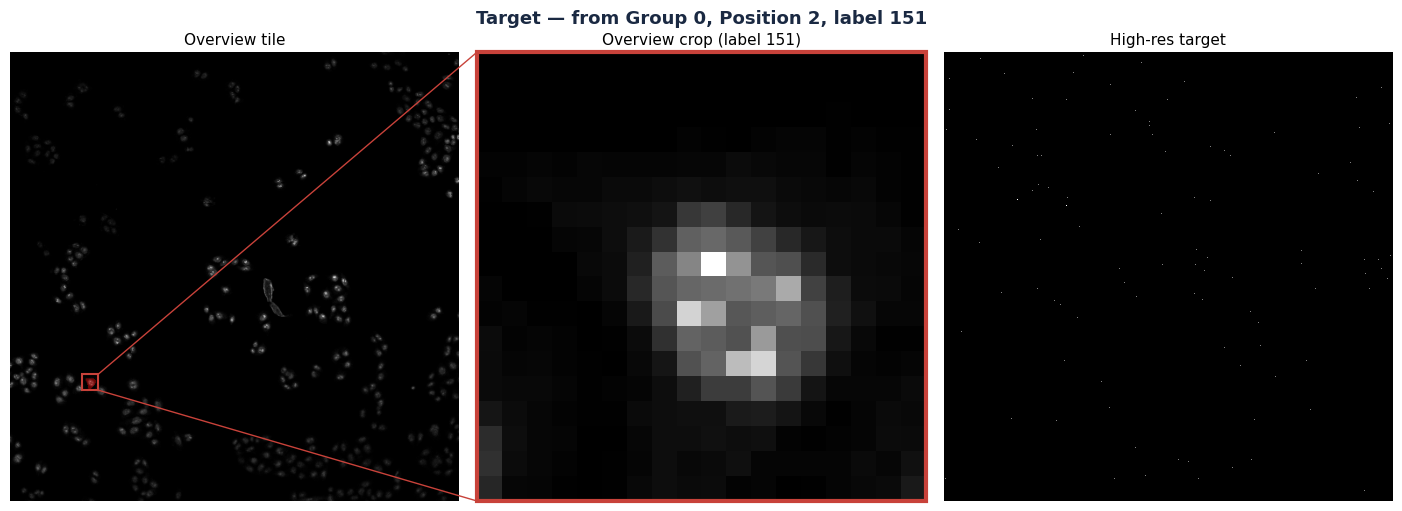

[2/15] Group 0, Position 0, label 712  src=(30905, 16618)  ok  tz=6206.2


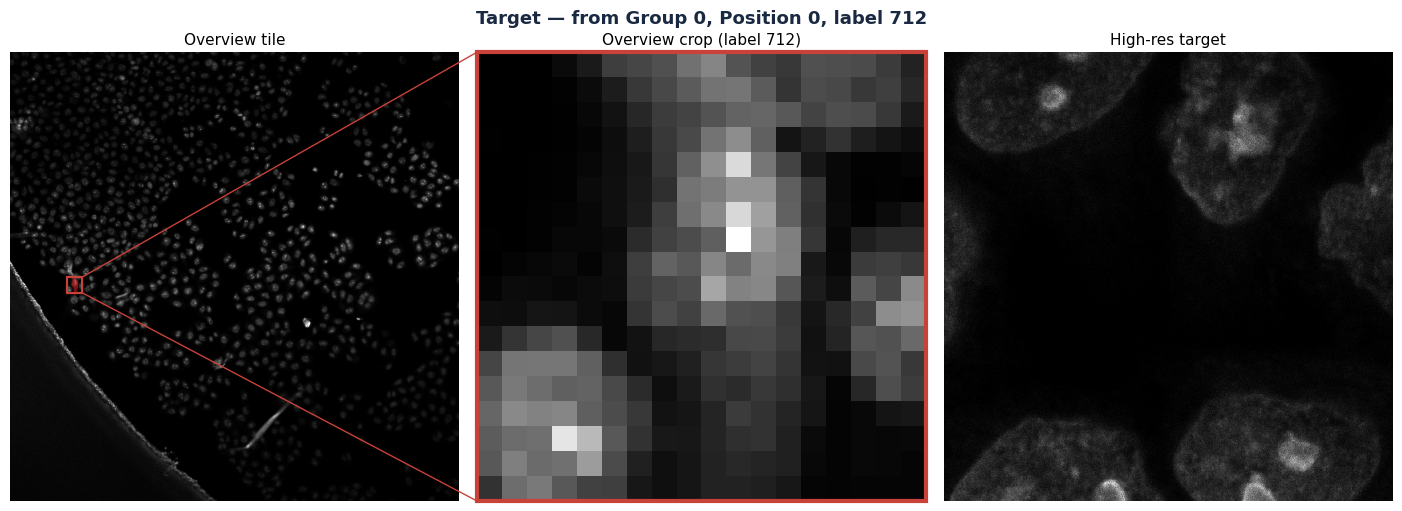

[3/15] Group 0, Position 2, label 78  src=(30914, 19520)  ok  tz=6215.5


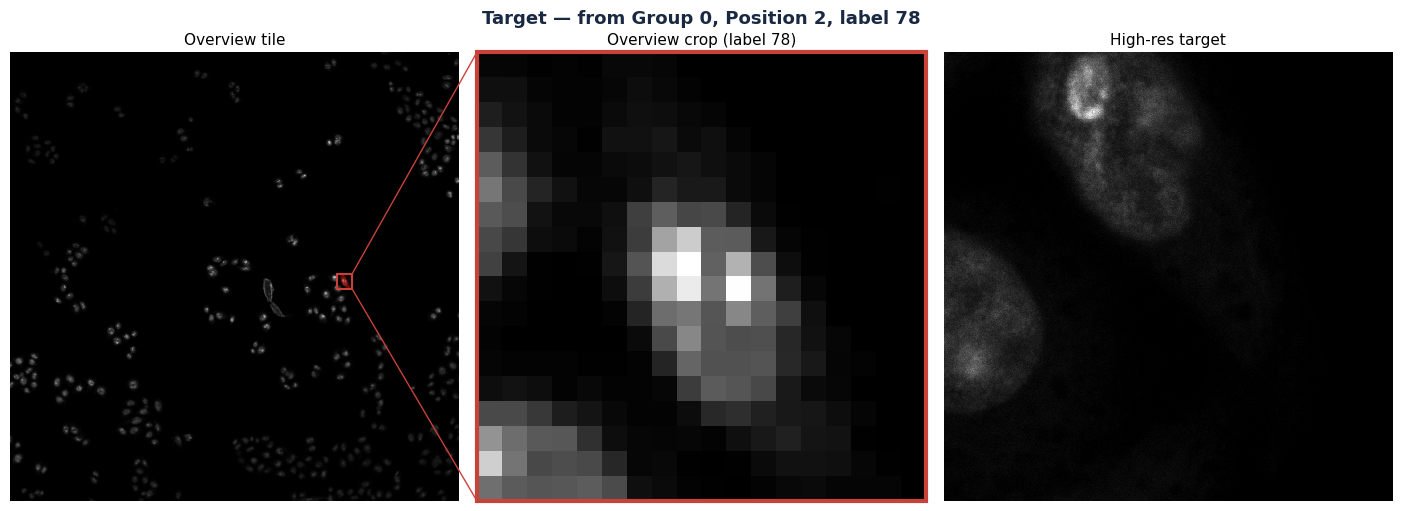

[4/15] Group 0, Position 0, label 606  src=(31011, 17328)  ok  tz=6206.2


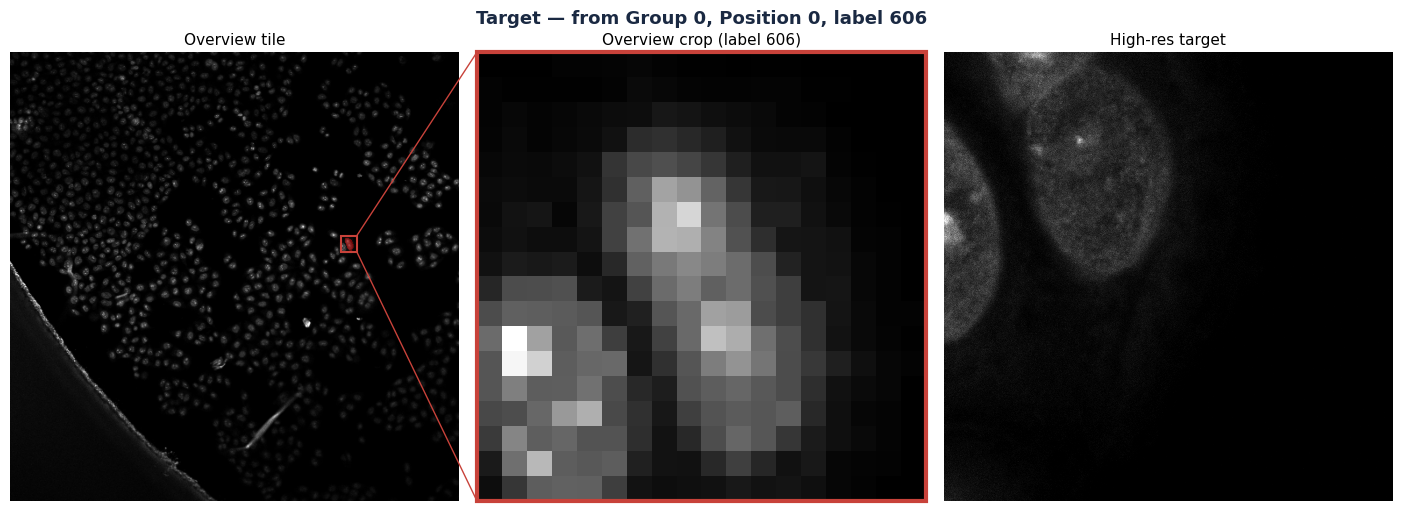

[5/15] Group 0, Position 4, label 185  src=(31893, 18256)  ok  tz=6198.2


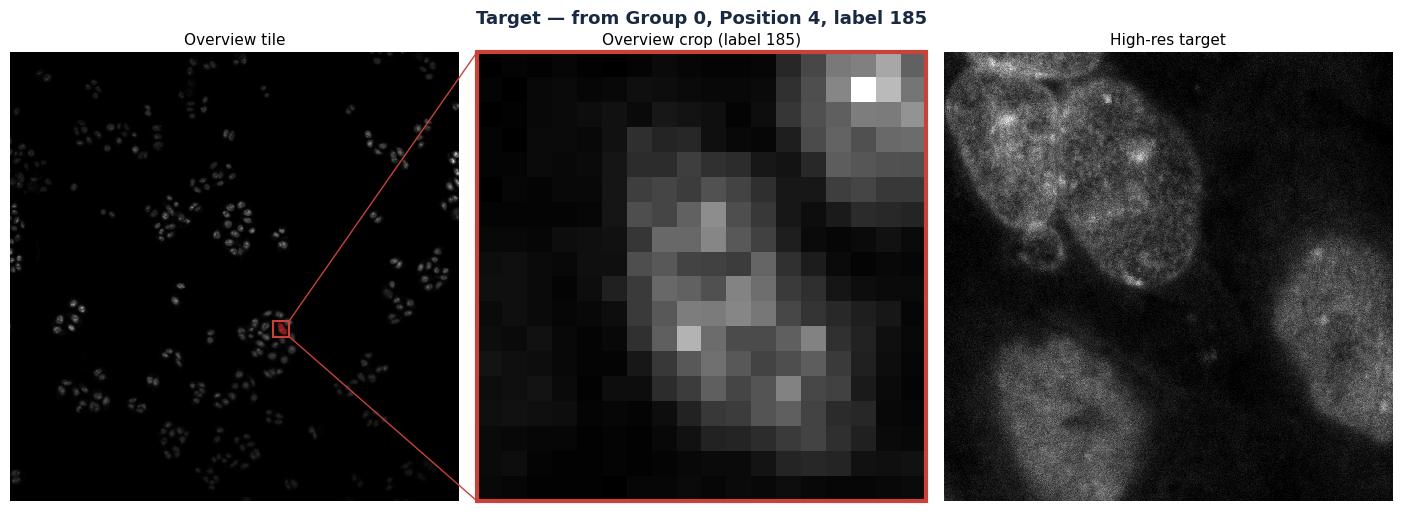

[6/15] Group 0, Position 3, label 622  src=(31926, 17145)  ok  tz=6193.5


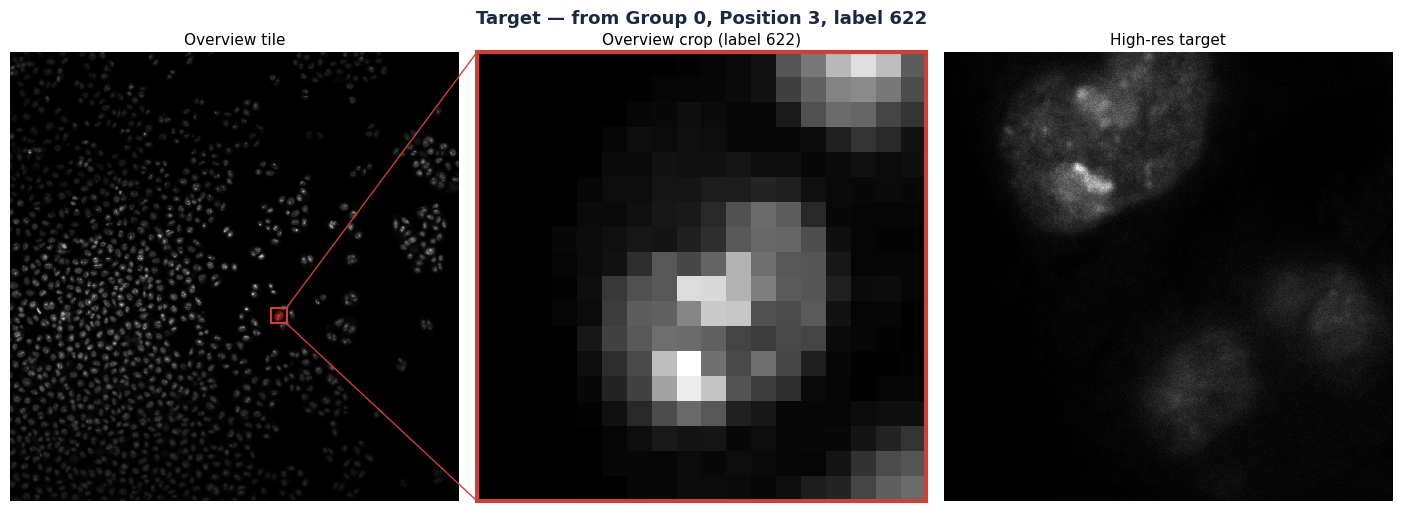

[7/15] Group 0, Position 5, label 146  src=(32015, 19588)  ok  tz=6202.8


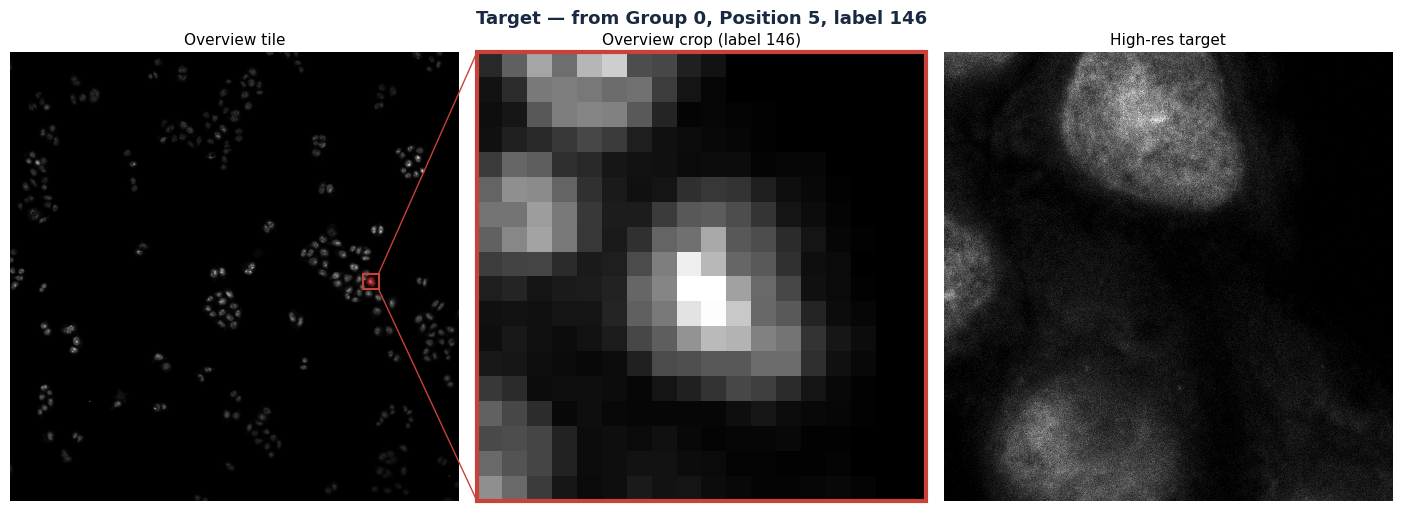

[8/15] Group 0, Position 3, label 482  src=(32069, 17210)  ok  tz=6193.5


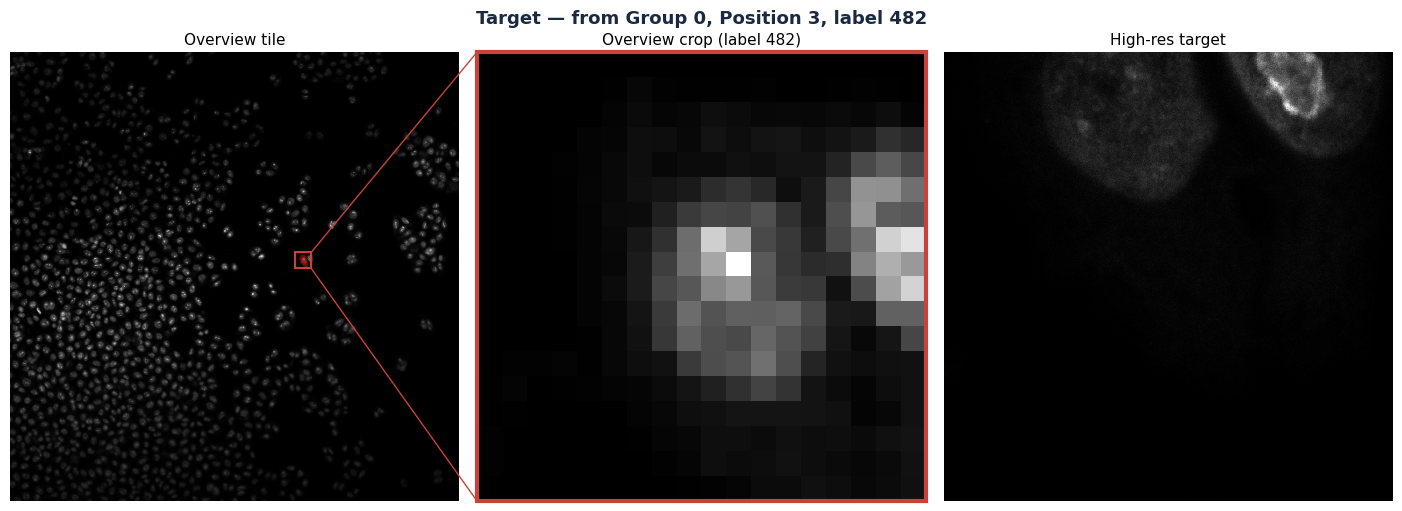

[9/15] Group 0, Position 5, label 112  src=(32150, 19612)  ok  tz=6202.8


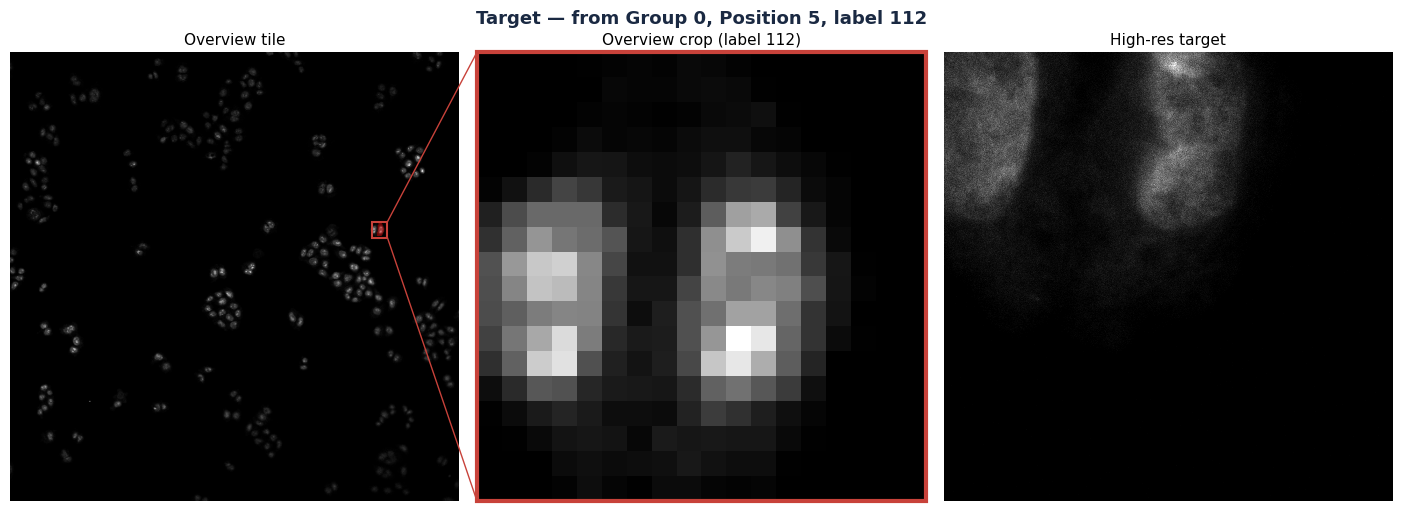

[10/15] Group 0, Position 6, label 376  src=(33045, 16634)  ok  tz=6180.8


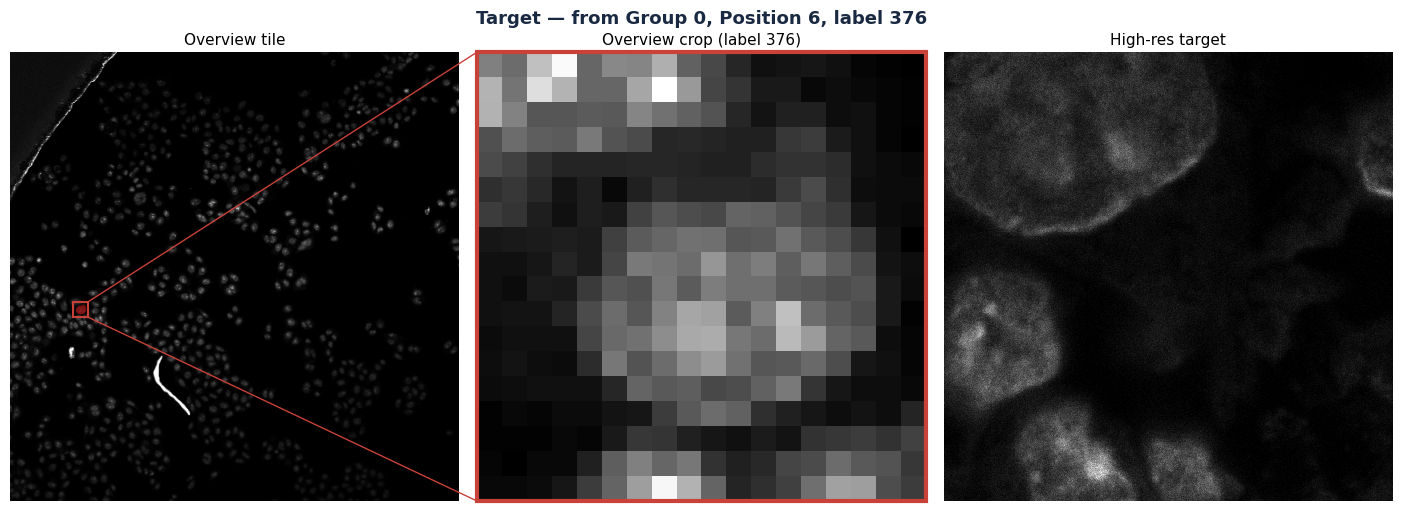

[11/15] Group 0, Position 8, label 80  src=(33133, 19657)  ok  tz=6190.1


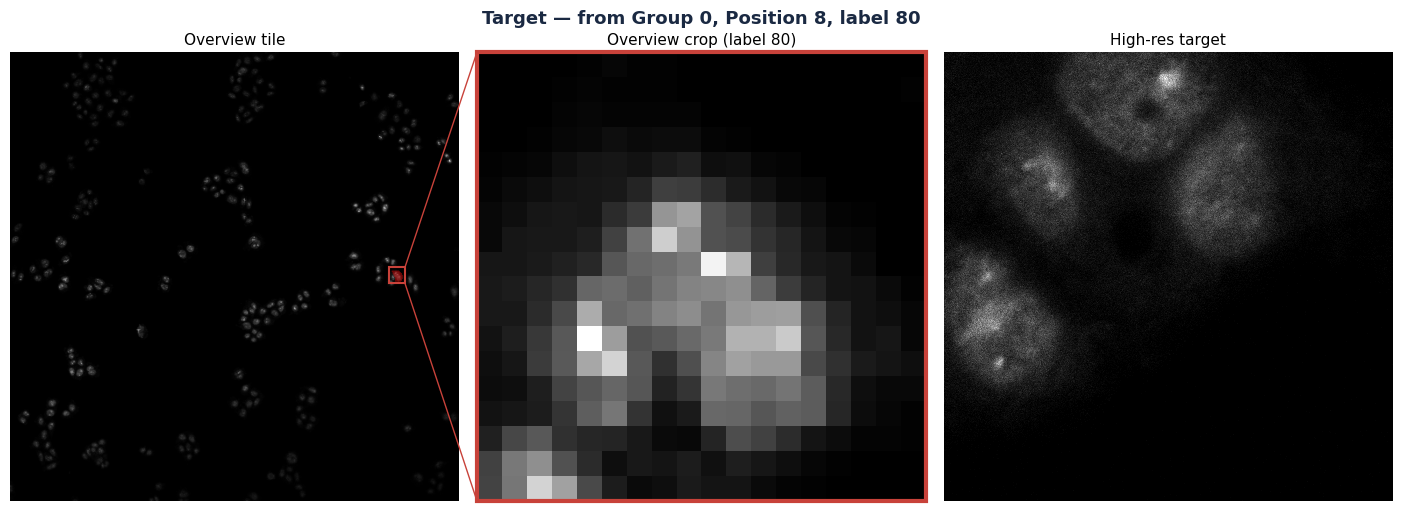

[12/15] Group 0, Position 8, label 70  src=(33185, 19544)  ok  tz=6190.1


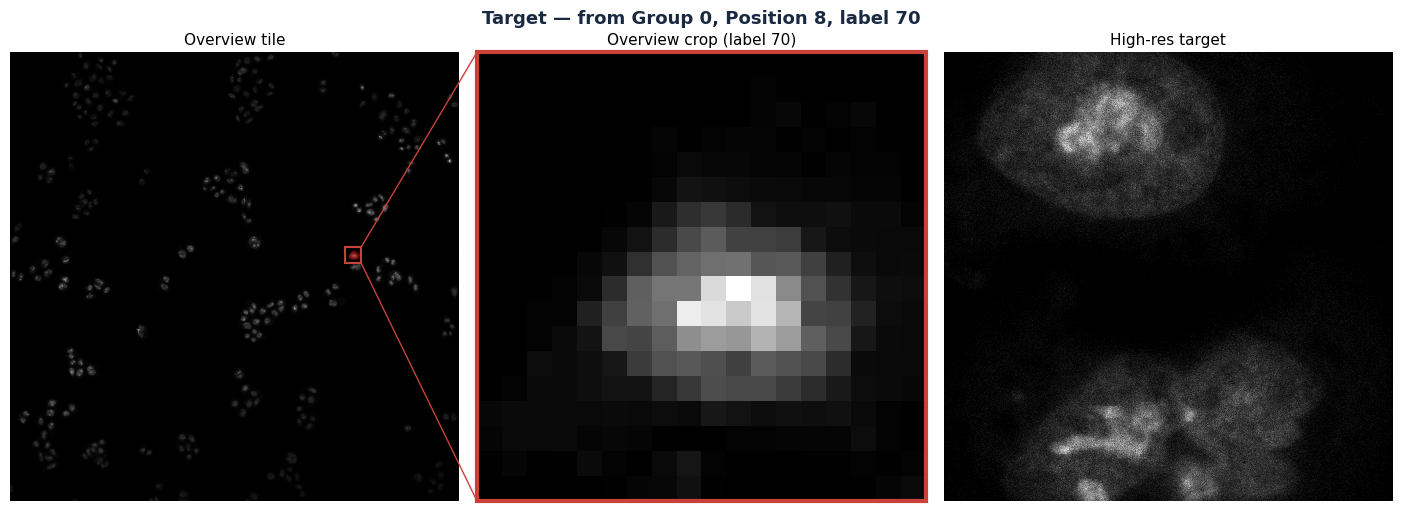

[13/15] Group 0, Position 7, label 172  src=(33203, 18426)  ok  tz=6185.5


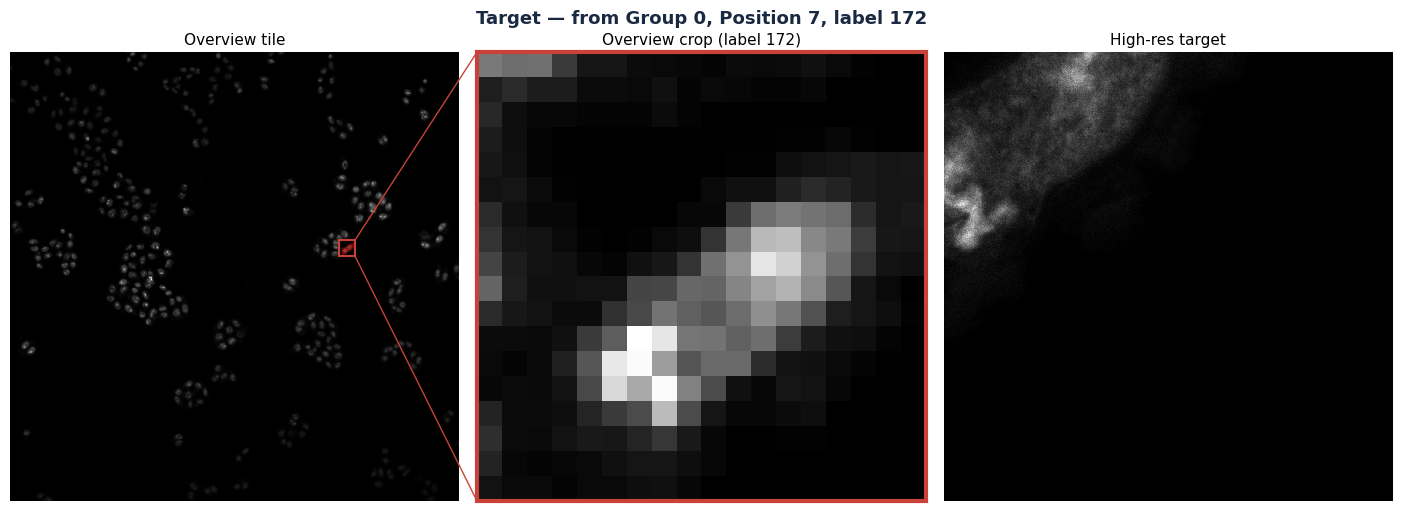

[14/15] Group 0, Position 6, label 300  src=(33218, 17219)  ok  tz=6180.8


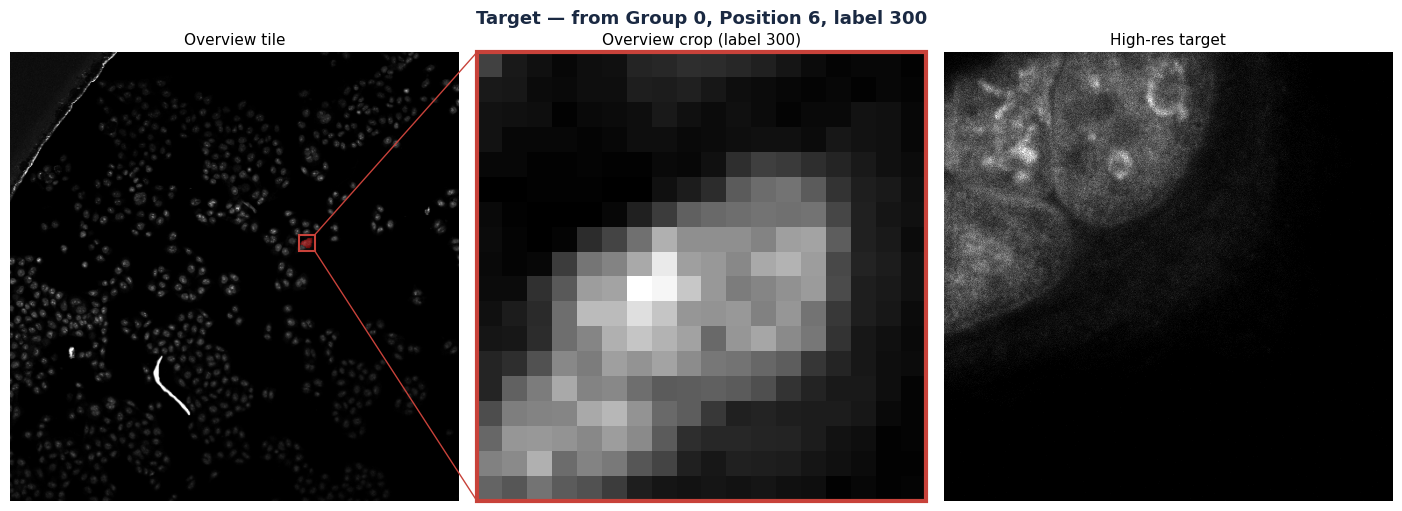

[15/15] Group 0, Position 7, label 146  src=(33286, 18517)  ok  tz=6185.5


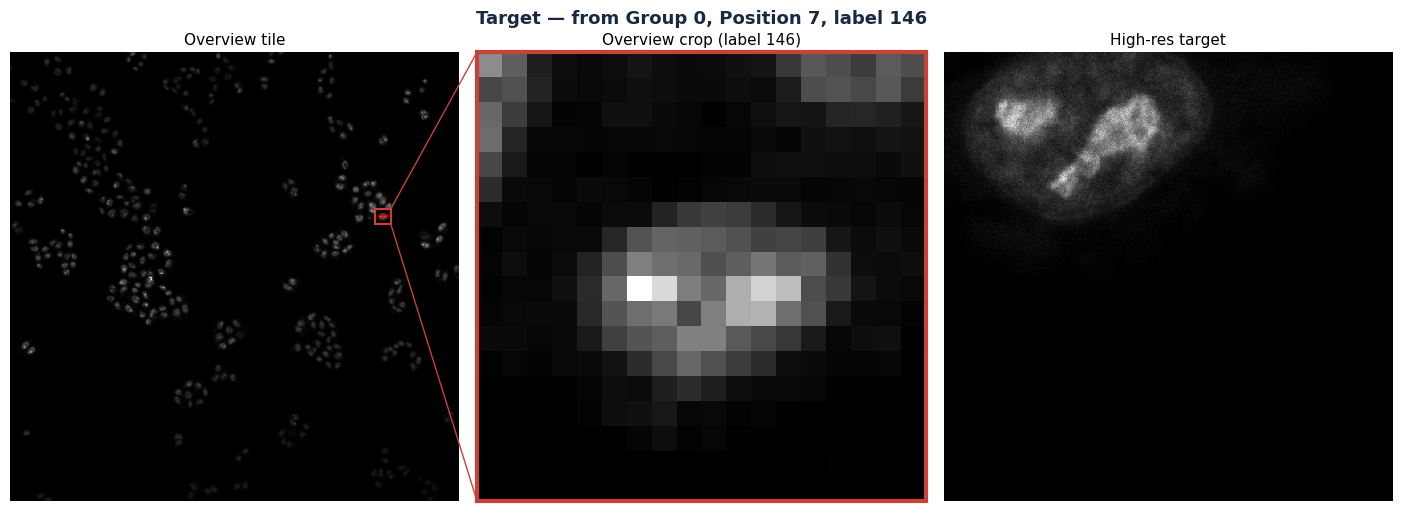


[step 5] Done: 15/15 targets acquired
[step 5] Template restored.


In [11]:
from workflow import acquire_targets

records = acquire_targets(ctx, picks)


## Step 6 — Finish

Writes `run_summary.json`, plots the results, and shuts down the engine.

The Cleanup cell below is a safety backstop for interrupted runs — not part of the normal path.

In [ ]:
from workflow import write_summary, plot_results, finish
from workflow.selection import load_overview_result

# Reload from disk so the finish cell is consistent with selection above
# (restart-between-selection-and-finish is NOT supported -- picks,
# selection, and records must still be in-kernel here).
overview = load_overview_result(ctx.run.layout.analysis_dir("overview-scan"))
write_summary(ctx, focus_map, overview, picks, selection, records)
plot_results(ctx, focus_map, picks, records)
finish(ctx)

In [ ]:
# Cleanup -- safety backstop for interrupted runs. Shuts down the
# analysis engine. Does NOT disconnect the LAS X client; it persists
# until kernel restart. Always safe to run.
try:
    ctx.shutdown()
except NameError:
    pass
